In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import seaborn as sns

import os
import pickle

from scipy.stats import pearsonr, ttest_ind
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, roc_curve
import statsmodels.formula.api as smf
from statannotations.Annotator import Annotator

In [3]:
if os.getcwd().endswith('/notebooks/figures'):
    os.chdir('../../')

In [4]:
from src.model import kuramotoattractor, linearreg, mlmodel
from src.dataproc import ccutils, utils
from src.visualize import cycleviz
from src.model import hierarchmllinreg as hieml

### Supporting functions

In [5]:
mcoeff_dict = {'stimaucbetween':'SPA(7AM-11AM)', 'stimaucoutside':'SPA(11AM-7AM)', 'stimauc':'SPA(24h)',
                'sin_stim': 'sin($\phi^{s}_{t}$)', 'cos_stim': 'cos($\phi^{s}_{t}$)', 
                'left_right_peakgap_prev':r'$|\phi^{l}_{t-6mo} - \phi^{r}_{t-6mo}|$', 
               'total_amp_prev':  '$A^{l}_{t-6mo} + A^{r}_{t-6mo}$',
                'cycle_amp_prev': '$A^{c}_{t-6mo}$', 'sin_cycle_prev': 'sin($\phi^{c}_{t-6mo}$)', 'cos_cycle_prev':'cos($\phi^{c}_{t-6mo}$)',
                'cycle_amp_prev_signed': '$\hat{sg} * A^{c}_{t-6mo}$',
                'left_amp_prev': '$A^{l}_{t-6mo}$', 'sin_left_prev': 'sin($\phi^{l}_{t-6mo}$)', 'cos_left_prev': 'cos($\phi^{l}_{t-6mo}$)',
                'right_amp_prev': '$A^{r}_{t-6mo}$', 'sin_right_prev': 'sin($\phi^{r}_{t-6mo}$)', 'cos_right_prev': 'cos($\phi^{r}_{t-6mo}$)'}

In [6]:
### common variables
osccolordict = {'left':'tab:blue', 'right':'tab:orange', 'stim':'tab:red', 'cday':'gold', 'cnight':'black'}
coupling_const_list = ['K_left_right', 'K_left_stim', 'K_left_cday', 'K_left_cnight', 
                       'K_right_left', 'K_right_stim', 'K_right_cday', 'K_right_cnight']

In [7]:
dayclus_peakphase = 15 * np.pi / 12
nightclus_peakphase = 3 * np.pi / 12
sunmarker = '$\u2600$'
moonmarker = '$\u263D$'

In [8]:
#### Last updated on 6/21/2026 to align with the definition in Ankit's STM paper
def szred_to_responder(rednum):
    if rednum > 0.9:
        return 'SR'
    elif rednum < 0.5:
        return 'NR'
    else:
        return 'IR'

### Load files

In [9]:
# save flag
save_flag = False

In [10]:
#### paths
patient_list = ccutils.final_patient_list()
attbrstfile = 'data/processed/kuramotoattractor/fitted_couplings_attractor_brain_stim_24Sep2025.csv'  # fitted coupling constants
asresdf_dir = 'data/processed/kuramotoattractor/altstimpersample/'  # alternate stimulation results

# coupling strength prediction models
klrmodel_path = 'data/processed/kuramotoattractor/Klr_pred_models.pkl'
kstimmodel_path = 'data/processed/kuramotoattractor/Kstim_pred_models.pkl'
aucintmodel_path = 'data/processed/kuramotoattractor/hour_auc_interval_map.pkl'
aucconmodel_path = 'data/processed/kuramotoattractor/hour_auc_converse_map.pkl'

#### output figures directory
outfig_dir = 'output/circpaper_figures/fig07/'
outsupfig_dir = 'output/circpaper_figures/supp/'

In [11]:
### file with cycle information and fitted coupling constants
regdf = pd.read_csv(attbrstfile)  # use pre-saved dataframe
regdf['fc_sim_hr'] = regdf.apply(lambda row: kuramotoattractor.fc_similarity_hour(row), axis=1)

# sin and cos of peak times
for col in ['left_peakphase_prev','right_peakphase_prev', 'left_peakphase', 'right_peakphase', 'stim_peakphase']:
    if 'prev' in col:
        colsuffix = col.split('_')[0] + '_prev'
    else:
        colsuffix = col.split('_')[0]
        
    regdf[f'sin_{colsuffix}'] = np.sin(regdf[col])
    regdf[f'cos_{colsuffix}'] = np.cos(regdf[col])

# summary features of FC-CC cycles
regdf['left_right_peakgap_prev'] = regdf.apply(lambda x: ccutils.angle_gap(x, 'left_peaktime_prev', 'right_peaktime_prev'), 
                                  axis=1)
regdf['total_amp_prev'] = regdf['left_amp_prev'] + regdf['right_amp_prev'] 
regdf['peaksync'] = regdf.apply(lambda x: ccutils.peak_sync_from_angles(x['left_peakphase'], x['right_peakphase']), axis=1)

In [12]:
#### alternate stimulation models
# coupling and stimulation AUC prediction models
klrmodel = pickle.load(open(klrmodel_path, 'rb'))
kstimmodel = pickle.load(open(kstimmodel_path, 'rb'))
aucintmodel = pickle.load(open(aucintmodel_path, 'rb'))
aucconmodel = pickle.load(open(aucconmodel_path, 'rb'))

In [13]:
# alternate stimulation results
asresdf_filelist = sorted([item for item in os.listdir(asresdf_dir) if 'sindex' in item])
print('Num files:', len(asresdf_filelist))

# full alt stim results df
fasdf = pd.concat([pd.read_csv(asresdf_dir + fn) for fn in asresdf_filelist], axis=0, ignore_index=True)

# only keep the cases for which ssterm has converged (<1e-5)
fasdf.drop(index=fasdf.index[fasdf['ssterm'] > 1e-5], inplace=True)
print(fasdf.shape[0], len(asresdf_filelist) * 24)

# indices available from alternate stimulation analysis
asindices = sorted(fasdf['sampleindex'].unique())

Num files: 161
3853 3864


In [14]:
# outcome for patients included in the analysis
longi_patcodes_path = 'data/RNSdata/Outcome/Hippo_longitudinal_outcomes_postprocessed_2025April08.csv'
lgpatcodesdf = pd.read_csv(longi_patcodes_path) # longitudinal outcomes
outcomedf = lgpatcodesdf.loc[lgpatcodesdf['npe_code'].isin(patient_list)].copy()
ccutils.round_half_year_days(outcomedf, colname='days_from_implant')
outcomedf['dur_approxdiff'] = (outcomedf['dur_halfyr'] - outcomedf['days_from_implant']).abs()
outcomedf = outcomedf.sort_values(by='dur_approxdiff').drop_duplicates(subset=['npe_code', 'dur_halfyr'], keep='first').sort_index()
outcomedf['Responder_Type'] = outcomedf['sz_red'].apply(lambda x: szred_to_responder(x))

### Figure 7B: Coupling constants

In [15]:
# only samples with good fit for regression
fcsim_hour_threshold = 1
gfregdf = regdf.loc[regdf['fc_sim_hr'] < fcsim_hour_threshold].copy() 

In [16]:
stim_cols = ['stimauc', 'stimaucbetween', 'stimaucoutside', 'sin_stim', 'cos_stim']
cycle_left_cols = ['left_amp_prev', 'sin_left_prev', 'cos_left_prev']
cycle_right_cols = ['right_amp_prev', 'sin_right_prev', 'cos_right_prev']

# only left FC-CC (cycle 1)
flatregdf_left = gfregdf[['npecode', 'dur_day'] + stim_cols + cycle_left_cols + ['K_left_stim']].copy()
flatregdf_left.rename(columns=dict(zip(cycle_left_cols, [item.replace('left','cycle') for item in cycle_left_cols])), 
                      inplace=True)
flatregdf_left.rename(columns={'K_left_stim':'K_stim'}, inplace=True)
flatregdf_left['cycle'] = 1

# only right FC-CC (cycle 2)
flatregdf_right = gfregdf[['npecode', 'dur_day'] + stim_cols + cycle_right_cols + ['K_right_stim']].copy()
flatregdf_right.rename(columns=dict(zip(cycle_right_cols, [item.replace('right','cycle') for item in cycle_right_cols])), 
                       inplace=True)
flatregdf_right.rename(columns={'K_right_stim':'K_stim'}, inplace=True)
flatregdf_right['cycle'] = -1

# concatenate the two
flatregdf = pd.concat((flatregdf_left, flatregdf_right), axis=0, ignore_index=True)

# include variations of K_stim
flatregdf['K_stim_sign'] = flatregdf['K_stim'].apply(lambda x: np.sign(x))

In [17]:
### recursive feature elimination
regfeat_cols = ['cycle_amp_prev_signed', 'sin_cycle_prev', 'cos_cycle_prev', 
                'stimaucoutside', 'stimaucbetween', 'sin_stim', 'cos_stim']

yvar = 'K_stim'

mlfeats = ['sin_cycle_prev', 'stimaucoutside', 'stimaucbetween', 'sin_stim', 'cos_stim']
mlout = 'K_stim_sign'


final_regfeats = hieml.recursive_feature_elimination(regdf=flatregdf, 
                                                     full_feature_list=regfeat_cols, yvar=yvar, 
                                                     mlfeats=mlfeats, mlout=mlout,
                                                     cv_folds_list=patient_list, cv_var='npecode', 
                                                     app='kuramoto',
                                                     remove_outliers=True)

print('!!!!!!!! Final feature list:', final_regfeats, '!!!!!!!!!!!!!')

Removed outliers. Num entries: 164.


Cross-validation complete.
Significance counts of each feature:
 cycle_amp_prev_signed__pvalue     5
sin_cycle_prev__pvalue           26
cos_cycle_prev__pvalue            4
stimaucoutside__pvalue            0
stimaucbetween__pvalue           23
sin_stim__pvalue                  0
cos_stim__pvalue                  5
dtype: int64
Removed outliers. Num entries: 164.


Cross-validation complete.
Significance counts of each feature:
 cycle_amp_prev_signed__pvalue     5
sin_cycle_prev__pvalue           26
cos_cycle_prev__pvalue            8
stimaucbetween__pvalue           25
cos_stim__pvalue                  7
dtype: int64
!!!!!!!! Final feature list: ['cycle_amp_prev_signed', 'sin_cycle_prev', 'cos_cycle_prev', 'stimaucbetween', 'cos_stim'] !!!!!!!!!!!!!


In [18]:
### cross-validation
print(final_regfeats)

lmpreddf, lmmoddict, hiemlpreddf = hieml.cross_validation(regdf=flatregdf, 
                                                          regfeat_cols=final_regfeats, yvar=yvar, 
                                                          mlfeats=mlfeats, mlout=mlout,
                                                          cv_folds_list=patient_list, cv_var='npecode', 
                                                          app='kuramoto',
                                                          remove_outliers=True)

['cycle_amp_prev_signed', 'sin_cycle_prev', 'cos_cycle_prev', 'stimaucbetween', 'cos_stim']
Removed outliers. Num entries: 164.


Cross-validation complete.


In [19]:
roc_auc_score(hiemlpreddf['gt'], hiemlpreddf['modpred']) #, roc_auc_score(mlpreddf.loc[hiemlpreddf.index]['gt'], mlpreddf.loc[hiemlpreddf.index]['modpred'])

0.6266406757634828

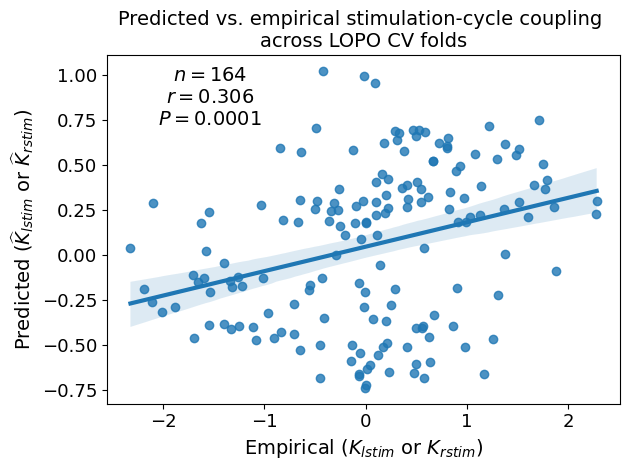

In [20]:
# scatter plot

corrval = pearsonr(lmpreddf['gt'], lmpreddf['modpred'])

# model prediction
ax = sns.regplot(data=lmpreddf, x='gt', y='modpred', label='Model prediction', 
                 color='tab:blue', line_kws={'linewidth':3})

# annotations
ax.text(x=0.2, y=0.8, s='$n=%d$\n$r=%0.3f$\n$P=%0.4f$'%(lmpreddf.shape[0], 
                                                     corrval.statistic, corrval.pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

# aesthetics
ax.set_xlabel(r'Empirical ($K_{lstim}$ or $K_{rstim}$)', fontsize=14)
ax.set_ylabel(r'Predicted ($\widehat{K}_{lstim}$ or $\widehat{K}_{rstim}$)', fontsize=14)
ax.tick_params(labelsize=13)

ax.set_title('Predicted vs. empirical stimulation-cycle coupling \nacross LOPO CV folds', fontsize=14)

plt.tight_layout()
if save_flag:
    plt.savefig(outfig_dir + "Kstim_scatter.pdf", dpi=300)

plt.show()

In [21]:
corrval

PearsonRResult(statistic=0.30563412983309435, pvalue=6.898941912938844e-05)

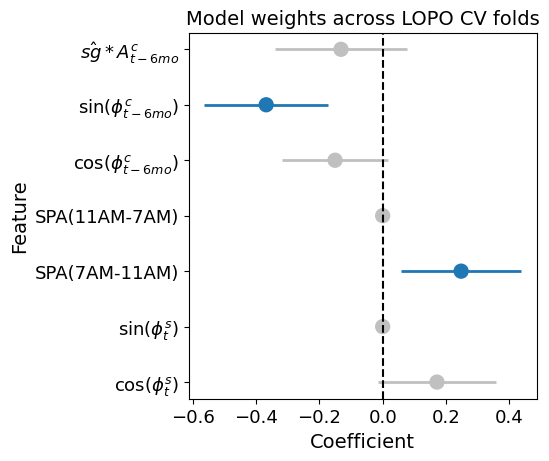

In [22]:
lmsummary = hieml.summarize_model_cv(lmmoddict, cv_var='npecode')
effectsize = hieml.effect_size_across_folds(lmsummary)
effectsize = utils.include_excluded_features_in_effectsize_df(effectsize, regfeat_cols)

escolordict = {1:'tab:blue', -1:'silver'}


fig, ax = plt.subplots(1,1, figsize=(5.35, 4.5), layout='constrained')


ax.scatter(effectsize['coef'].values, effectsize['xticks'].values, s=100, 
           c=[escolordict[item] for item in effectsize['sig'].values])
ax.hlines(y=effectsize['xticks'].values, xmin=effectsize['lower'].values, xmax=effectsize['upper'].values, 
             linewidth=2, colors=[escolordict[item] for item in effectsize['sig'].values])
ax.axvline(x=0, color='black', linestyle='--')
ax.set_yticks(ticks=effectsize['xticks'].values, 
              labels=[mcoeff_dict[item] for item in effectsize.index], fontsize=13)

ax.set_ylabel('Feature', fontsize=14)
ax.set_xlabel('Coefficient', fontsize=14)
ax.tick_params(labelsize=13)
ax.set_title('Beta weights', fontsize=14)

ax.set_title('Model weights across LOPO CV folds', fontsize=14)

if save_flag:
    plt.savefig(outsupfig_dir + 'insilico_Kstim_modelweights.pdf', dpi=300)

plt.show()

### Supplementary: Kbrain prediction and model weights

In [23]:
regfeat_cols = ['left_amp_prev', 'sin_left_prev', 'cos_left_prev',
                'right_amp_prev', 'sin_right_prev', 'cos_right_prev',
                'left_right_peakgap_prev', 'total_amp_prev']

yvar = 'K_left_right'

final_regfeats = linearreg.recursive_feature_elimination(regdf=gfregdf, 
                                                         full_feature_list=regfeat_cols, yvar=yvar, 
                                                         cv_folds_list=patient_list, cv_var='npecode', 
                                                         remove_outliers=True)

print('!!!!!!!! Final feature list:', final_regfeats, '!!!!!!!!!!!!!')

Removed outliers. Num entries: 72.
Cross-validation complete.
Significance counts of each feature:
 left_amp_prev__pvalue               0
sin_left_prev__pvalue               0
cos_left_prev__pvalue              25
right_amp_prev__pvalue              0
sin_right_prev__pvalue              0
cos_right_prev__pvalue              0
left_right_peakgap_prev__pvalue    25
total_amp_prev__pvalue              0
dtype: int64
Removed outliers. Num entries: 79.
Cross-validation complete.
Significance counts of each feature:
 cos_left_prev__pvalue              27
left_right_peakgap_prev__pvalue    27
dtype: int64
!!!!!!!! Final feature list: ['cos_left_prev', 'left_right_peakgap_prev'] !!!!!!!!!!!!!


In [24]:
### cross-validation with selected features
print('Features:', final_regfeats)
print('Output:', yvar)

lmpreddf, lmmoddict = linearreg.cross_validation(regdf=gfregdf,
                                                 regfeat_cols=final_regfeats, yvar=yvar, 
                                                 cv_folds_list=patient_list, cv_var='npecode', 
                                                 remove_outliers=True)

Features: ['cos_left_prev', 'left_right_peakgap_prev']
Output: K_left_right
Removed outliers. Num entries: 79.
Cross-validation complete.


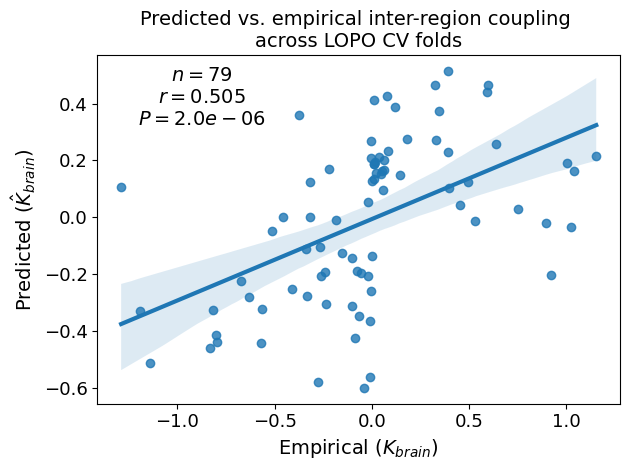

In [25]:
corrval = pearsonr(lmpreddf['gt'], lmpreddf['modpred'])

# model prediction
ax = sns.regplot(data=lmpreddf, x='gt', y='modpred', label='Model prediction', 
                 color='tab:blue', line_kws={'linewidth':3})


# annotations
ax.text(x=0.2, y=0.8, s='$n=%d$\n$r=%0.3f$\n$P=%0.1e$'%(lmpreddf.shape[0], 
                                                     corrval.statistic, corrval.pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

# aesthetics
ax.set_xlabel('Empirical ($K_{brain})$', fontsize=14)
ax.set_ylabel('Predicted ($\hat{K}_{brain}$)', fontsize=14)
ax.tick_params(labelsize=13)

ax.set_title(f'Predicted vs. empirical inter-region coupling \nacross LOPO CV folds', fontsize=14)

plt.tight_layout()
if save_flag:
    plt.savefig(outsupfig_dir + 'insilico_Kbrain_scatter.pdf', dpi=300)

plt.show()

In [26]:
corrval

PearsonRResult(statistic=0.5052784152760004, pvalue=2.0421859601049156e-06)

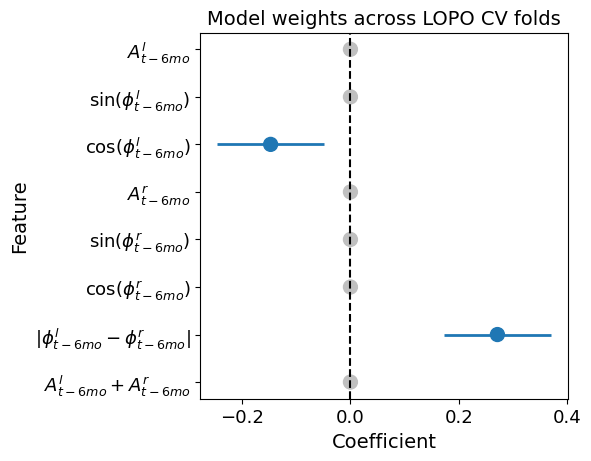

In [27]:
lmsummary = linearreg.summarize_model_cv(lmmoddict, cv_var='npecode')
effectsize = linearreg.effect_size_across_folds(lmsummary)
effectsize = utils.include_excluded_features_in_effectsize_df(effectsize, regfeat_cols)

escolordict = {1:'tab:blue', -1:'silver'}


fig, ax = plt.subplots(1,1, figsize=(5.8, 4.5), layout='constrained')


ax.scatter(effectsize['coef'].values, effectsize['xticks'].values, s=100, 
           c=[escolordict[item] for item in effectsize['sig'].values])
ax.hlines(y=effectsize['xticks'].values, xmin=effectsize['lower'].values, xmax=effectsize['upper'].values, 
             linewidth=2, colors=[escolordict[item] for item in effectsize['sig'].values])
ax.axvline(x=0, color='black', linestyle='--')
ax.set_yticks(ticks=effectsize['xticks'].values, 
              labels=[mcoeff_dict[item] for item in effectsize.index], fontsize=13)

ax.set_ylabel('Feature', fontsize=14)
ax.set_xlabel('Coefficient', fontsize=14)
ax.tick_params(labelsize=13)
ax.set_title('Beta weights', fontsize=14)

ax.set_title('Model weights across LOPO CV folds', fontsize=14)

if save_flag:
    plt.savefig(outsupfig_dir + 'insilico_Kbrain_modelweights.pdf', dpi=300)

plt.show()

## 7C: In silico for one example

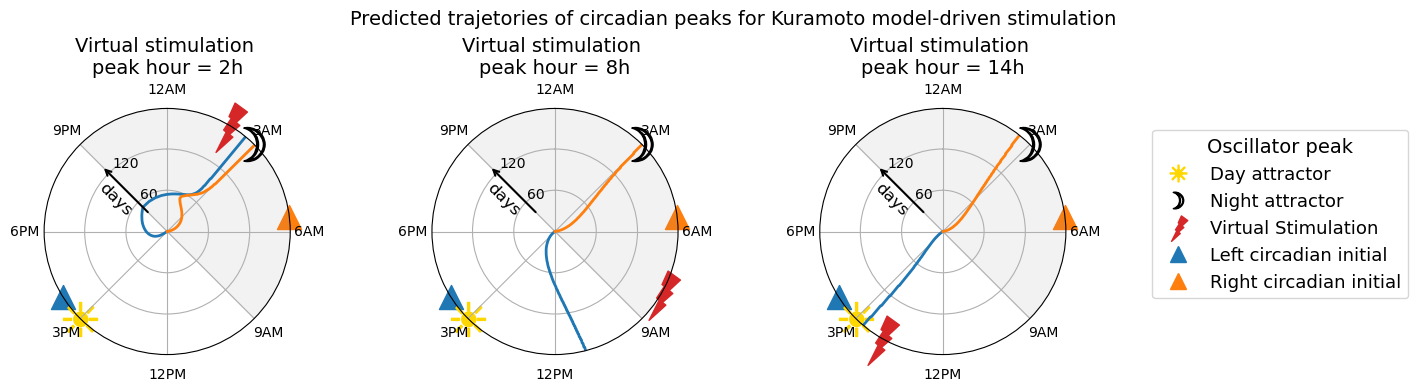

In [28]:
# check Kuramoto model forward solution for a given solution

df_index = 4
plot_stimhours = [2, 8, 14]
scaling_list = [20, 90, 90]
datrow = regdf.loc[df_index].copy()
pat_klrmodel = klrmodel[datrow['npecode']]
pat_kstimmodel = kstimmodel[datrow['npecode']]

# alter stimulation class instance
altsimu = kuramotoattractor.AlternateStimulation(datrow=datrow, klrmodel=pat_klrmodel, kstimmodel=pat_kstimmodel, 
                                                 aucintdict=aucintmodel, auccondict=aucconmodel)

###### plotting
ncols = 4
nrows = 1
fig, ax = plt.subplots(nrows, ncols, figsize=(3.8*ncols, 3.8*nrows), 
                       subplot_kw={'projection':'polar'}, layout='constrained')
fax = ax.flatten()

for ii in range(3):
    ### key and row
    kmindict, _, osppdf, _ = altsimu.kuramoto_sol_altstim(stimhour=plot_stimhours[ii], scaling=scaling_list[ii])
    
    #### plot the trajectories
    cycleviz.kuramoto_forward_trajectories(osppdf, hue_list=['left', 'right'], hue_colors=osccolordict,
                                           theta_left=-kmindict['theta_left_0'], theta_right=-kmindict['theta_right_0'], 
                                           fig=fig, ax=fax[ii], legend=False, markersize=300)
    
    # plot the final ground truth hour 
    rmax = fax[ii].get_rmax()
    # fax[ii].scatter(gt_theta_left_final, rmax, s=300, c='tab:blue', marker='*', clip_on=False)
    # fax[ii].scatter(gt_theta_right_final, rmax, s=300, c='tab:orange', marker='*', clip_on=False)

    fax[ii].scatter(dayclus_peakphase, rmax, s=600, c=osccolordict['cday'], marker=sunmarker, clip_on=False)
    fax[ii].scatter(nightclus_peakphase, rmax, s=600, c=osccolordict['cnight'], marker=moonmarker, clip_on=False)

    fax[ii].scatter(-kmindict['theta_stim_0'], rmax, s=1500, c=osccolordict['stim'], marker=cycleviz.lightning_bolt(), clip_on=False)

    fax[ii].set_title(f'Virtual stimulation \npeak hour = {plot_stimhours[ii]}h', fontsize=14)
    fax[ii].set_yticks([60, 120])

    # radial axis and label
    fax[ii].set_rlabel_position(-42)
    theta_9pm_rad = 21 * np.pi/12
    fax[ii].annotate('', xy=(theta_9pm_rad, rmax * 0.75), xytext=(theta_9pm_rad, rmax * 0.20),
                      xycoords='data', textcoords='data', arrowprops=dict(arrowstyle='->', lw=1.5, color='black'))
    fax[ii].text(0.96*theta_9pm_rad, rmax * 0.50, 'days', ha='center', va='center', fontsize=12, rotation=-45)

fax[3].set_visible(False)

fig.suptitle(f'Predicted trajetories of circadian peaks for Kuramoto model-driven stimulation', fontsize=14)

### fancy legend
# Define the styles and the separate labels
markers = [sunmarker, moonmarker, cycleviz.lightning_bolt(), '^', '^']
colors = [osccolordict[key] for key in ['cday', 'cnight', 'stim', 'left', 'right', 'left', 'right']]
legend_labels = ['Day attractor', 'Night attractor', 'Virtual Stimulation', 'Left circadian initial', 'Right circadian initial']

# Create a list to store the custom handles
custom_handles = []
for marker, color in zip(markers, colors):
    # Create a Line2D object with the desired properties
    if color == 'tab:red': markersize=20
    else: markersize=12
    handle = Line2D([0], [0], marker=marker, color=color, linestyle='', markersize=markersize, markerfacecolor=color)
    custom_handles.append(handle)

# We pass the manually created custom_handles and the separate legend_labels
fig.legend(custom_handles, legend_labels, fontsize=13, loc='center right', bbox_to_anchor=(0.95, 0.45), 
           title='Oscillator peak', title_fontsize=14, fancybox=True, shadow=False)


if save_flag:
    plt.savefig(outfig_dir + 'altstim_example.pdf', dpi=300)

plt.show()

### Supplement: In silico for one example ; unscaled trajectories

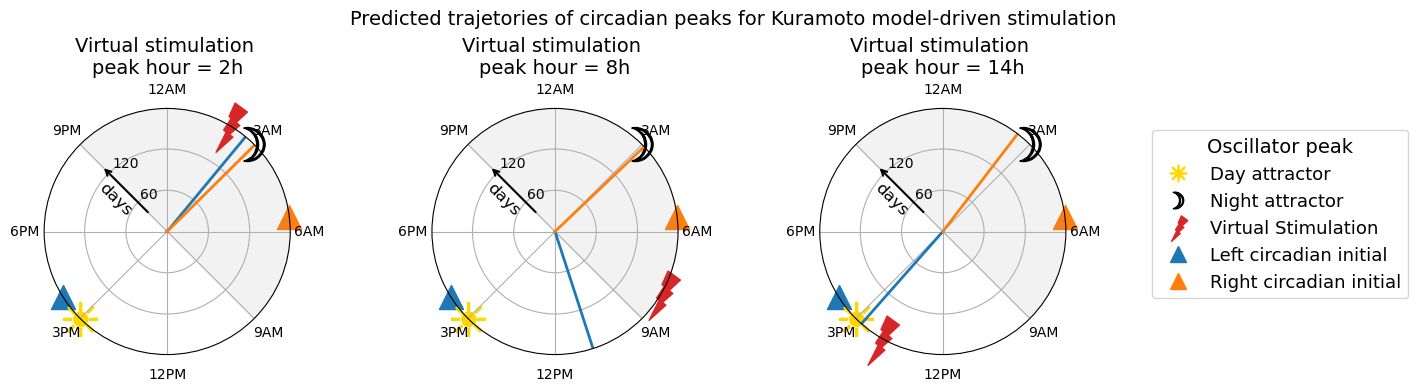

In [29]:
# check Kuramoto model forward solution for a given solution

df_index = 4
plot_stimhours = [2, 8, 14]
scaling_list = [1, 1, 1]
datrow = regdf.loc[df_index].copy()
pat_klrmodel = klrmodel[datrow['npecode']]
pat_kstimmodel = kstimmodel[datrow['npecode']]

# alter stimulation class instance
altsimu = kuramotoattractor.AlternateStimulation(datrow=datrow, klrmodel=pat_klrmodel, kstimmodel=pat_kstimmodel, 
                                                 aucintdict=aucintmodel, auccondict=aucconmodel)

###### plotting
ncols = 4
nrows = 1
fig, ax = plt.subplots(nrows, ncols, figsize=(3.8*ncols, 3.8*nrows), 
                       subplot_kw={'projection':'polar'}, layout='constrained')
fax = ax.flatten()

for ii in range(3):
    ### key and row
    kmindict, _, osppdf, _ = altsimu.kuramoto_sol_altstim(stimhour=plot_stimhours[ii], scaling=scaling_list[ii])
    
    #### plot the trajectories
    cycleviz.kuramoto_forward_trajectories(osppdf, hue_list=['left', 'right'], hue_colors=osccolordict,
                                           theta_left=-kmindict['theta_left_0'], theta_right=-kmindict['theta_right_0'], 
                                           fig=fig, ax=fax[ii], legend=False, markersize=300)
    
    # plot the final ground truth hour 
    rmax = fax[ii].get_rmax()
    # fax[ii].scatter(gt_theta_left_final, rmax, s=300, c='tab:blue', marker='*', clip_on=False)
    # fax[ii].scatter(gt_theta_right_final, rmax, s=300, c='tab:orange', marker='*', clip_on=False)

    fax[ii].scatter(dayclus_peakphase, rmax, s=600, c=osccolordict['cday'], marker=sunmarker, clip_on=False)
    fax[ii].scatter(nightclus_peakphase, rmax, s=600, c=osccolordict['cnight'], marker=moonmarker, clip_on=False)

    fax[ii].scatter(-kmindict['theta_stim_0'], rmax, s=1500, c=osccolordict['stim'], marker=cycleviz.lightning_bolt(), clip_on=False)

    fax[ii].set_title(f'Virtual stimulation \npeak hour = {plot_stimhours[ii]}h', fontsize=14)
    fax[ii].set_yticks([60, 120])

    # radial axis and label
    fax[ii].set_rlabel_position(-42)
    theta_9pm_rad = 21 * np.pi/12
    fax[ii].annotate('', xy=(theta_9pm_rad, rmax * 0.75), xytext=(theta_9pm_rad, rmax * 0.20),
                      xycoords='data', textcoords='data', arrowprops=dict(arrowstyle='->', lw=1.5, color='black'))
    fax[ii].text(0.96*theta_9pm_rad, rmax * 0.50, 'days', ha='center', va='center', fontsize=12, rotation=-45)

fax[3].set_visible(False)

fig.suptitle(f'Predicted trajetories of circadian peaks for Kuramoto model-driven stimulation', fontsize=14)

### fancy legend
# Define the styles and the separate labels
markers = [sunmarker, moonmarker, cycleviz.lightning_bolt(), '^', '^']
colors = [osccolordict[key] for key in ['cday', 'cnight', 'stim', 'left', 'right', 'left', 'right']]
legend_labels = ['Day attractor', 'Night attractor', 'Virtual Stimulation', 'Left circadian initial', 'Right circadian initial']

# Create a list to store the custom handles
custom_handles = []
for marker, color in zip(markers, colors):
    # Create a Line2D object with the desired properties
    if color == 'tab:red': markersize=20
    else: markersize=12
    handle = Line2D([0], [0], marker=marker, color=color, linestyle='', markersize=markersize, markerfacecolor=color)
    custom_handles.append(handle)

# We pass the manually created custom_handles and the separate legend_labels
fig.legend(custom_handles, legend_labels, fontsize=13, loc='center right', bbox_to_anchor=(0.95, 0.45), 
           title='Oscillator peak', title_fontsize=14, fancybox=True, shadow=False)


if save_flag:
    plt.savefig(outsupfig_dir + 'insilico_altstim_example_unscaled.pdf', dpi=300)

plt.show()

### Supplement: Average circadian concordance

In [30]:
#### mean and confidence interval across available samples for a given hour
altstimresp = pd.concat((fasdf.groupby(by='stimhour')['aspeaksync'].mean().rename('mean'),   # mean
                         1.96 * fasdf.groupby(by='stimhour')['aspeaksync'].sem().rename('ci')),  # confidence interval = 1.96 * SE
                        axis=1, ignore_index=False)

altstimresp.reset_index(inplace=True)
                          
altstimresp.loc[24] = altstimresp.loc[0] # repeat midnight to complete polar plot

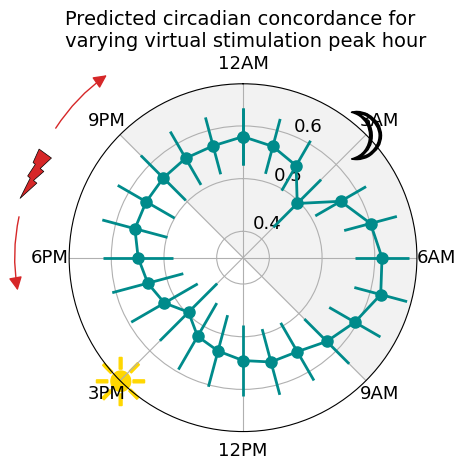

In [31]:
time_low, time_high = 9, 21
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})

ax.errorbar(x=np.pi / 12 * altstimresp['stimhour'], y=altstimresp['mean'], yerr=altstimresp['ci'], 
            color='darkcyan', linestyle='-', linewidth=2, marker='o', markersize=8, elinewidth=2)
ax.axvspan(xmin=(time_high-24) * np.pi/12, 
           xmax=time_low * np.pi/12, color='grey', alpha=0.1)
ax.set_ylim([0.35, 0.68])
avgplt_rmax = ax.get_rmax()
ax.scatter(dayclus_peakphase, avgplt_rmax, s=1200, c=osccolordict['cday'], marker=sunmarker, clip_on=False)
ax.scatter(nightclus_peakphase, avgplt_rmax, s=1200, c=osccolordict['cnight'], marker=moonmarker, clip_on=False)

# --- NEW: single stimulation marker at 7:30PM with bidirectional sweep arcs ---
stim_center_hour = 19.5  # 7:30PM
stim_center_angle = np.pi / 12 * stim_center_hour
sweep_halfwidth = np.pi / 9

icon_radius = 1.15 * avgplt_rmax

# the representative stimulation marker
ax.scatter(stim_center_angle, icon_radius, marker=cycleviz.lightning_bolt(),
           s=1500, c=osccolordict['stim'], edgecolor='black', linewidth=0.5,
           clip_on=False, zorder=4)

# arrows
cycleviz.outer_arrow_arc(ax=ax, start_angle=stim_center_angle - 0.2, arrow_radius=icon_radius, arrow_length=sweep_halfwidth, 
                         arc_curve=1, direction='clockwise', color=osccolordict['stim'])
cycleviz.outer_arrow_arc(ax=ax, start_angle=stim_center_angle + 0.2, arrow_radius=icon_radius, arrow_length=sweep_halfwidth, 
                         arc_curve=1, direction='anticlockwise', color=osccolordict['stim'])

ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_xticks(ticks=np.arange(0,8)*np.pi/4, 
              labels=['12AM', '3AM', '6AM', '9AM', '12PM', '3PM', '6PM', '9PM'])
ax.set_ymargin(0.05)
ax.set_yticks(ticks=[0.4, 0.5, 0.6])
plt.title('Predicted circadian concordance for \n varying virtual stimulation peak hour', fontsize=14)
plt.tick_params(labelsize=13)

plt.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'insilico_avgcirconc.pdf', dpi=300)
    
plt.show()

### Supplement: Mixed effects modeling

In [32]:
### relate the peak sync values with stim AUC outside 7-11AM

aucconmap = pickle.load(open('data/processed/kuramotoattractor/hour_auc_converse_map.pkl','rb'))
pstoszmod_dict = pickle.load(open('data/processed/kuramotoattractor/psalpha_to_szred_linmod.pkl','rb'))  # to predict seizure reduction from peak sync alpha

altpsoutdf = altstimresp.copy()
altpsoutdf.drop(index=24, inplace=True)
altpsoutdf['auc_converse'] = altpsoutdf['stimhour'].apply(lambda x: aucconmap[x])

In [33]:
# dataframe for mixed effect modeling
mxmregdf = fasdf[['sampleindex', 'stimhour', 'aspeaksync']].merge(right=regdf[['index', 'npecode', 'dur_day']], how='left', 
                                                                  left_on='sampleindex', right_on='index')

mxmregdf['auc_converse'] = mxmregdf['stimhour'].apply(lambda x: aucconmap[x])

In [34]:
# statsmodels needs a unique ID for the nested grouping factor (month within patient)
mxmregdf["patient_month"] = mxmregdf["npecode"] + "_" + mxmregdf["dur_day"].astype(str)
mxmregdf["auc_converse_std"] = ( mxmregdf["auc_converse"] - mxmregdf["auc_converse"].mean() ) / mxmregdf["auc_converse"].std()
mxmregdf["aspeaksync_std"] = (mxmregdf["aspeaksync"] - mxmregdf["aspeaksync"].mean()) / mxmregdf["aspeaksync"].std()

# ------------------------------------------------------------------
# 2. Fit: biomarker ~ stimulation_dose + (1 | patient/month)
#    - "groups" = outer grouping factor (patient)
#    - "vc_formula" = variance component for month nested within patient
# ------------------------------------------------------------------
vc = {"dur_day": "0 + C(patient_month)"}  # random intercept for each patient-month combo

mxmmodel = smf.mixedlm(
    "aspeaksync_std ~ auc_converse",
    data=mxmregdf,
    groups=mxmregdf["npecode"],     # outer random effect: patient
    vc_formula=vc,            # nested random effect: month within patient
    re_formula="1"            # random intercept only at patient level
)

mxmresult = mxmmodel.fit(reml=True)
print(mxmresult.summary())

nobs = mxmresult.nobs
validation_beta = mxmresult.params['auc_converse']
validation_pvalue = mxmresult.pvalues['auc_converse']

           Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: aspeaksync_std
No. Observations: 3853    Method:             REML          
No. Groups:       28      Scale:              0.1889        
Min. group size:  24      Log-Likelihood:     -2625.6919    
Max. group size:  432     Converged:          Yes           
Mean group size:  137.6                                     
-------------------------------------------------------------
              Coef.   Std.Err.    z     P>|z|  [0.025  0.975]
-------------------------------------------------------------
Intercept      0.178     0.134   1.322  0.186  -0.086   0.441
auc_converse  -0.015     0.007  -2.048  0.041  -0.030  -0.001
Group Var      0.253     0.248                               
dur_day Var    0.598     0.173                               



In [35]:
## mixed effects model coefficients for plotting
mxmmodel_raw = smf.mixedlm(
    "aspeaksync ~ auc_converse",
    data=mxmregdf,
    groups=mxmregdf["npecode"],     # outer random effect: patient
    vc_formula=vc,            # nested random effect: month within patient
    re_formula="1"            # random intercept only at patient level
)
mxmresult_raw = mxmmodel_raw.fit(reml=True)
validation_beta_raw = mxmresult_raw.params['auc_converse']
validation_intercept_raw = mxmresult_raw.params['Intercept']

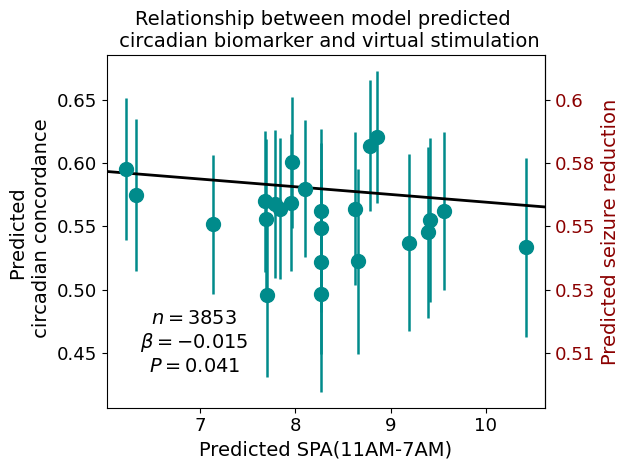

In [36]:
fig, ax = plt.subplots(1,1)

#### scatter plot of mean and confidence interval
ax.errorbar(x=altpsoutdf['auc_converse'], y=altpsoutdf['mean'], yerr=altpsoutdf['ci'], 
             linestyle='', marker='o', markersize=10, elinewidth=1.8, color='darkcyan')

xlims = ax.get_xlim()

#### linear regression line
plt.plot(np.linspace(xlims[0], xlims[1], 50), 
         validation_beta_raw * np.linspace(xlims[0], xlims[1], 50) + validation_intercept_raw, 
         color='black', linewidth=2)

ax.set_xlim(xlims)

##### annotations
ax.text(x=0.2, y=0.1, s='$n=%d$\n$\\beta=%0.3f$\n$P=%0.3f$'%(nobs, validation_beta, validation_pvalue), 
        transform=ax.transAxes, fontsize=14, color='black', ha='center')

###### seizure reduction ylabel
ps_scaling = 1 # fasdf['aspeaksync_total'].mean()  # scaling from normalized peak sync to peak sync
pred_ps_list = ps_scaling * ax.get_yticks()   # peak sync for the yticks
pred_ps_df = pd.DataFrame(pred_ps_list, columns=['peakhour_local-alpha'])

# predict seizure reduction from peak sync alpha values
pred_sz_df = []
for key, linmod in pstoszmod_dict.items():
    pred_sz_df.append(linmod.test_linreg_model(pred_ps_df))
# seizure reduction corresponding to the yticks' peak sync alpha
pred_sz_red = np.round( pd.concat(pred_sz_df, ignore_index=False, axis=1).mean(axis=1).values, 2 )

# add a secondary axis
ax2 = ax.secondary_yaxis('right')
ax2.set_yticks(ticks=ax.get_yticks(), labels=pred_sz_red)

#### aesthetics
ax.set_xlabel('Predicted SPA(11AM-7AM)', fontsize=14)
ax.set_ylabel('Predicted \n circadian concordance', fontsize=14)
ax.set_title('Relationship between model predicted \n circadian biomarker and virtual stimulation', fontsize=14)
ax.tick_params(labelsize=13)

ax2.set_ylabel('Predicted seizure reduction', color='darkred', fontsize=14)
ax2.tick_params(axis='y', labelcolor='darkred', labelsize=13)

fig.tight_layout()

if save_flag:
    plt.savefig(outsupfig_dir + 'insilico_nus_replicate.pdf', dpi=300)

plt.show()

### 7D: Responder status and virtual stimulation

In [37]:
# fasdf with name and six-month epoch
faswndf = fasdf[['sampleindex', 'stimhour', 'aspeaksync']].merge(regdf[['index','npecode','dur_day','stim_peaktime', 'peaksync']],
                                                                 how='left', left_on='sampleindex', right_on='index')
faswndf.rename(columns={'stimhour':'virstimhour', 'stim_peaktime':'obstimhour'}, inplace=True)

# include outcome information
faswnwodf = faswndf.merge(outcomedf[['npe_code','dur_halfyr','sz_red','Responder_Type']], how='left', 
                          left_on=['npecode','dur_day'], right_on=['npe_code','dur_halfyr'])

faswnwodf.dropna(axis=0, inplace=True)
faswnwodf.drop(columns=['sampleindex','npe_code','dur_halfyr'], inplace=True)

In [38]:
def circular_diff(a, b, period=24):
    d = np.abs(a - b)
    return np.minimum(d, period - d)

max_vals = faswnwodf.groupby(['npecode', 'dur_day'])['aspeaksync'].transform('max')
tied_max = faswnwodf[faswnwodf['aspeaksync'] == max_vals]

maxvccdf = tied_max.groupby(['npecode', 'dur_day']).agg(virstimhours_at_max=('virstimhour', list), 
                                                        obstimhour=('obstimhour', 'first'), 
                                                        aspeaksync=('aspeaksync', 'first'),
                                                        sz_red=('sz_red', 'first'), 
                                                        Responder_Type=('Responder_Type', 'first')).reset_index()

maxvccdf['vodisc'] = maxvccdf.apply(lambda row: circular_diff(np.array(row['virstimhours_at_max']), row['obstimhour']).min(), axis=1)

In [39]:
print(ttest_ind(maxvccdf.loc[(maxvccdf['Responder_Type']=='SR') & (maxvccdf['aspeaksync'] > 0.95)]['vodisc'], 
                maxvccdf.loc[(maxvccdf['Responder_Type']=='NR') & (maxvccdf['aspeaksync'] > 0.95)]['vodisc']))
print(maxvccdf.loc[(maxvccdf['aspeaksync'] > 0.9)]['Responder_Type'].value_counts())

TtestResult(statistic=-3.3196053357527453, pvalue=0.003418950555433547, df=20.0)
Responder_Type
SR    14
IR     8
NR     8
Name: count, dtype: int64


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

SR vs. NR: P = 0.0034 (n1=14 vs n2=8)


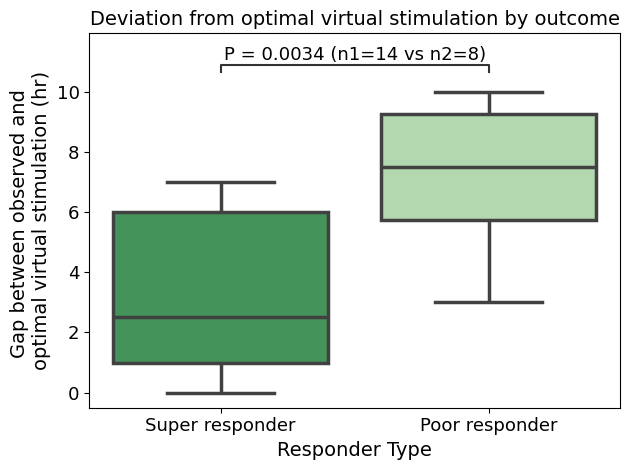

In [40]:
boxdf = maxvccdf.loc[(maxvccdf['Responder_Type'].isin(['SR','NR'])) & (maxvccdf['aspeaksync'] > 0.95)].copy()

boxorder = ['SR', 'NR']
boxtickdict = {'SR': 'Super responder', 'NR':'Poor responder'}
boxpairs = [('SR', 'NR')]

ax = sns.boxplot(data=boxdf, x='Responder_Type', y='vodisc', order=boxorder, 
                 showfliers=True, linewidth=2.5, 
                 palette='Greens', hue='Responder_Type', legend=False)  # boxes

ax.set_xlabel('Responder Type', fontsize=14)
ax.set_ylabel('Gap between observed and \noptimal virtual stimulation (hr)', fontsize=14)
ax.set_title('Deviation from optimal virtual stimulation by outcome', fontsize=14)

ax.set_xticks(ticks=[0,1], labels=[boxtickdict[key] for key in boxorder], fontsize=13)
ax.tick_params(labelsize=13)

n_counts = boxdf.groupby('Responder_Type')['vodisc'].count()

annotator = Annotator(ax, boxpairs, data=boxdf, x='Responder_Type', y='vodisc', order=boxorder)
annotator.configure(test='t-test_ind', loc='inside', fontsize=13)
annotator.apply_test()

pval = annotator.annotations[0].data.pvalue
n1 = n_counts[boxpairs[0][0]]
n2 = n_counts[boxpairs[0][1]]

custom_label = f"P = {pval:.4f} (n1={n1} vs n2={n2})"
annotator.set_custom_annotations([custom_label])
annotator.annotate()

plt.tight_layout()

if save_flag:
    plt.savefig(outfig_dir + 'virobstim_outcomediff.pdf', dpi=300)

plt.show()

### 7E: In silico outcome comparison

In [41]:
# compare the best achieved peak sync from alternate stim with the observed peak sync
bestaspeaksync = fasdf.groupby(by='sampleindex')['aspeaksync'].max()
obpeaksync = regdf.loc[regdf['index'].isin(asindices)]['peaksync']

In [42]:
insiliimp = pd.DataFrame({'Stimulation':['Model-based Optimal', 'Observed'],
                          'Counts':[(bestaspeaksync > 0.95).sum(), (obpeaksync > 0.95).sum()],
                          'dummyx':[1,0]})

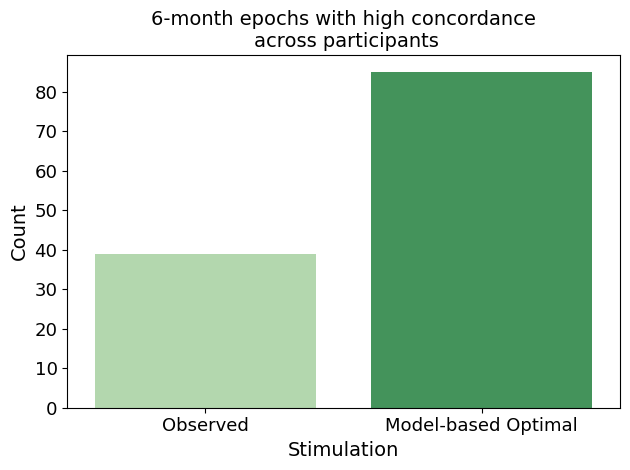

In [43]:
barorder = ['Observed', 'Model-based Optimal']
ax = sns.barplot(insiliimp, x='dummyx', hue='Stimulation', y='Counts', 
                 hue_order=barorder, legend=False, palette='Greens')

ax.set_xlabel('Stimulation', fontsize=14)
ax.set_ylabel('Count', fontsize=14)
ax.set_title('6-month epochs with high concordance\n across participants', fontsize=14)

ax.set_xticks(ticks=[0,1], labels=barorder, fontsize=13)
ax.tick_params(labelsize=13)

plt.tight_layout()

if save_flag:
    plt.savefig(outfig_dir + 'insilico_outcomes.pdf', dpi=300)

plt.show()